In [57]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import DataLoader, Dataset

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

device = torch.device('mps' if torch.backends.mps.is_available() else 'cpu')
random_state = 42
np.random.seed(random_state)
torch.manual_seed(random_state)
if torch.backends.mps.is_available():
    torch.cuda.manual_seed(random_state)

In [58]:
data_path = 'Data/NonLinear_data.npy'
data = np.load(data_path, allow_pickle=True).item()
X, y = data['X'], data['labels']
X

array([[ 0.00000000e+00,  0.00000000e+00],
       [ 9.60083739e-04,  1.00552794e-02],
       [ 1.04586376e-02,  1.72840539e-02],
       [ 8.79222065e-04,  3.02902726e-02],
       [ 9.91726687e-03,  3.91680265e-02],
       [ 6.77282958e-03,  5.00488652e-02],
       [ 1.41908220e-02,  5.89212623e-02],
       [ 3.11579559e-02,  6.34718176e-02],
       [-8.03243759e-03,  8.04078719e-02],
       [ 4.44744542e-02,  7.92873618e-02],
       [ 4.42749312e-02,  9.07897074e-02],
       [ 1.35659734e-02,  1.10279841e-01],
       [ 4.51006429e-02,  1.12509157e-01],
       [ 8.18222344e-02,  1.02704724e-01],
       [ 1.02915603e-01,  9.69862772e-02],
       [ 1.09463907e-01,  1.04759220e-01],
       [ 9.88552373e-02,  1.27857052e-01],
       [ 1.33913469e-01,  1.07489394e-01],
       [ 1.67286205e-01,  7.12262365e-02],
       [ 1.70560114e-01,  8.79899069e-02],
       [ 1.40953043e-01,  1.44721808e-01],
       [ 1.28611110e-01,  1.68684887e-01],
       [ 1.42427503e-01,  1.70578786e-01],
       [ 1.

In [59]:
y

array([0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
       0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
       0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
       0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
       0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1,
       1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1,
       1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1,
       1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1,
       1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1,
       1, 1, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2,
       2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2,
       2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2,
       2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2,
       2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2], d

In [60]:
print(f'Shape of X: {X.shape}')
print(f'Shape of y: {y.shape}')
print(f'First 5 rows of X: {X[:5]}')
print(f'First 5 labels: {y[:5]}')

Shape of X: (300, 2)
Shape of y: (300,)
First 5 rows of X: [[0.         0.        ]
 [0.00096008 0.01005528]
 [0.01045864 0.01728405]
 [0.00087922 0.03029027]
 [0.00991727 0.03916803]]
First 5 labels: [0 0 0 0 0]


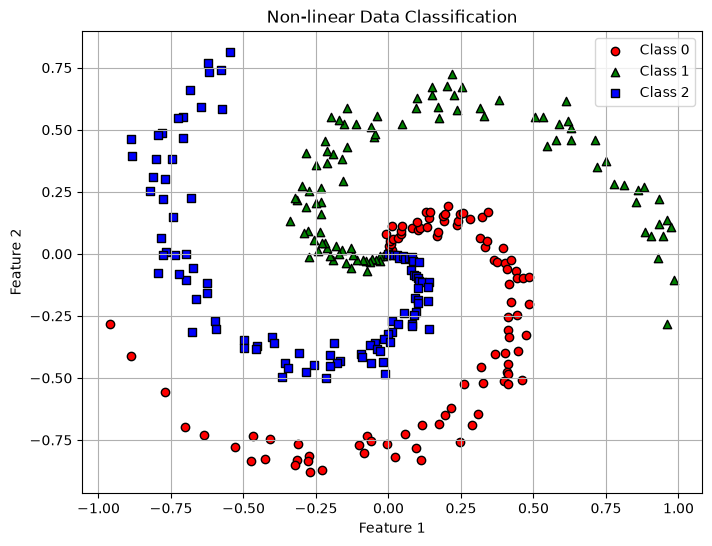

In [61]:
colors = ['red', 'green', 'blue']

markers = ['o', '^', 's']
plt.figure(figsize=(8, 6))

for i, class_label in enumerate(np.unique(y)):
    plt.scatter(
        X[y == class_label, 0],
        X[y == class_label, 1],
        c = colors[i],
        marker=markers[i],
        label = f'Class {class_label}',
        edgecolors='k'
    )

plt.title('Non-linear Data Classification')
plt.xlabel('Feature 1')
plt.ylabel('Feature 2')
plt.legend()
plt.grid(True)
plt.show()

In [62]:
val_size = 0.2
test_size = 0.125
is_shuffle = True
X_train, X_val, y_train, y_val = train_test_split(
    X, y,
    test_size = val_size,
    random_state = random_state,
    shuffle = is_shuffle
)
X_train, X_test, y_train, y_test = train_test_split(
    X_train, y_train,
    test_size=test_size,
    random_state=random_state,
    shuffle=is_shuffle
)
print(X_train.shape)
print(X_val.shape)
print(X_test.shape)

(210, 2)
(60, 2)
(30, 2)


In [63]:
normalizer = StandardScaler()
X_train = normalizer.fit_transform(X_train)
X_val = normalizer.transform(X_val)
X_test = normalizer.transform(X_test)

X_train = torch.tensor(X_train, dtype = torch.float32)
X_val = torch.tensor(X_val, dtype = torch.float32)
X_test = torch.tensor(X_test, dtype = torch.float32)
y_train = torch.tensor(y_train, dtype = torch.long)
y_val = torch.tensor(y_val, dtype = torch.long)
y_test = torch.tensor(y_test, dtype = torch.long)

In [64]:
class CustomDataset(Dataset):
    def __init__(self, X, y):
        self.X = X
        self.y = y
    def __len__(self):
        return len(self.y)
    def __getitem__(self, index):
        return self.X[index], self.y[index]

In [65]:
batch_size = 32
train_dataset = CustomDataset(X_train, y_train)
val_dataset = CustomDataset(X_val, y_val)
test_dataset = CustomDataset(X_test, y_test)
train_loader = DataLoader(train_dataset, 
                          batch_size=batch_size,
                          shuffle=True)
val_loader = DataLoader(val_dataset,
                        batch_size=batch_size,
                        shuffle = True)
test_loader = DataLoader(test_dataset,
                         batch_size=batch_size,
                         shuffle=True)

In [66]:
class MLP(nn.Module):
    def __init__(self, input_dims, hidden_dims, output_dims):
        super(MLP, self).__init__()
        self.linear1 = nn.Linear(input_dims, hidden_dims)
        self.ouput = nn.Linear(hidden_dims, output_dims)
        self.relu = nn.ReLU()
    def forward(self, x):
        x = self.linear1(x)
        x = self.relu(x)
        out = self.ouput(x)
        return out.squeeze(1)


In [67]:
input_dims = X_train.shape[1]
output_dims = torch.unique(y_train).shape[0]
hidden_dims = 128
lr = 1e-1

model = MLP(input_dims=input_dims, hidden_dims=hidden_dims, output_dims=output_dims).to(device)
criterion = nn.CrossEntropyLoss()
optimizer = torch.optim.SGD(model.parameters(), lr = lr)

In [68]:
def compute_accuracy(y_hat, y_true):
    _, y_hat = torch.max(y_hat, dim = 1)
    correct = (y_hat == y_true).sum().item()
    accuracy = correct / len(y_true)
    return accuracy

In [ ]:
epochs = 100
train_losses = []
val_losses = []
train_accs = []
val_accs = []
for epoch in range(epochs):
    train_loss = 0.0
    train_target = []
    train_predict = []
    model.train()
    for X_samples, y_samples in train_loader:
        X_samples = X_samples.float().to(device)
        y_samples = y_samples.long().to(device)

        optimizer.zero_grad()
        outputs = model(X_samples)
        loss = criterion(outputs, y_samples)
        loss.backward()
        optimizer.step()
        train_loss += loss.item()
        train_predict.append(outputs.detach().cpu())
        train_target.append(y_samples.cpu())
    train_loss /= len(train_loader)
    train_losses.append(train_loss)

    train_predict = torch.cat(train_predict)
    train_target = torch.cat(train_target)
    train_acc = compute_accuracy(train_predict, train_target)
    train_accs.append(train_acc)

    val_loss = 0.0
    val_target = []
    val_predict = []
    model.eval()
    with torch.no_grad():
        for X_samples, y_samples in val_loader:
            X_samples = X_samples.float().to(device)
            y_samples = y_samples.to(device)

            outputs = model(X_samples)
            val_loss += criterion(outputs, y_samples).item()

            val_predict.append(outputs.cpu())
            val_target.append(y_samples.cpu())

        val_loss /= len(val_loader)
        val_losses.append(val_loss)

        val_predict = torch.cat(val_predict)
        val_target = torch.cat(val_target)
        val_acc = compute_accuracy(val_predict, val_target)
        val_accs.append(val_acc)


Text(0.5, 1.0, 'Validation Accuracy')

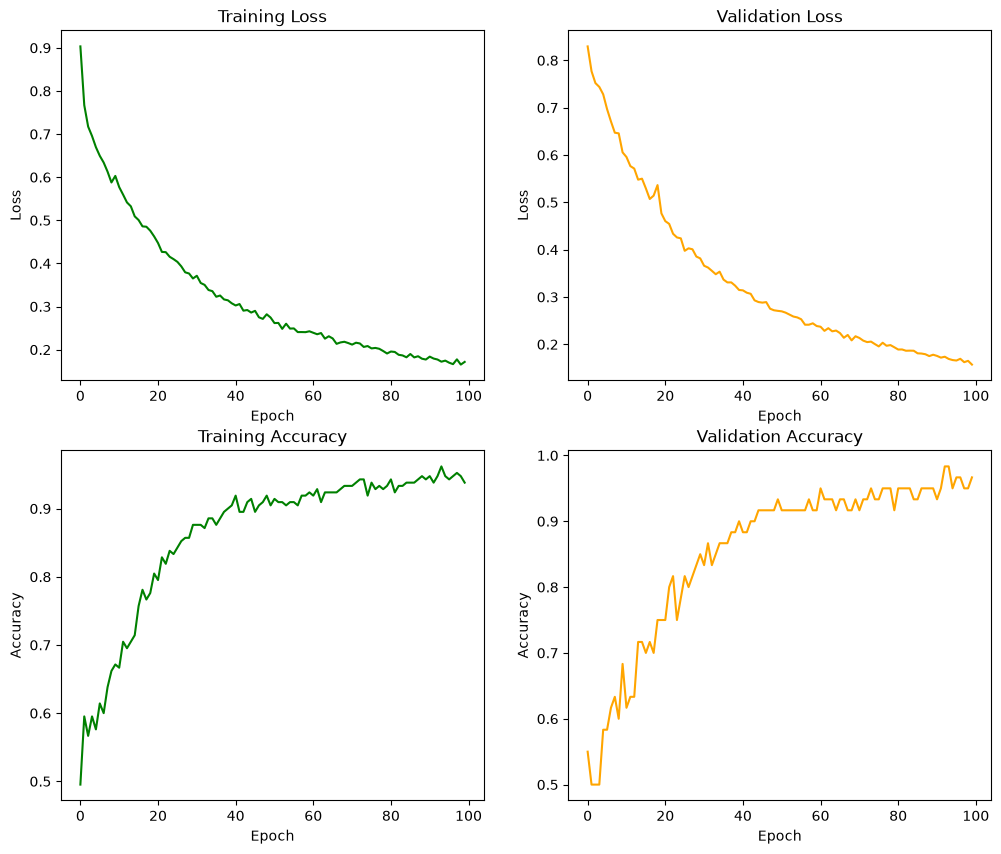

In [71]:
# Visualization
fig, ax = plt.subplots(2, 2, figsize = (12, 10))
ax[0, 0].plot(train_losses, color = 'green')
ax[0, 0].set(xlabel = 'Epoch', ylabel = 'Loss')
ax[0, 0].set_title('Training Loss')

ax[0, 1].plot(val_losses, color = 'orange')
ax[0, 1].set(xlabel = 'Epoch', ylabel = 'Loss')
ax[0, 1].set_title('Validation Loss')

ax[1, 0].plot(train_accs, color = 'green')
ax[1, 0].set(xlabel = 'Epoch', ylabel = 'Accuracy')
ax[1, 0].set_title('Training Accuracy')

ax[1, 1].plot(val_accs, color = 'orange')
ax[1, 1].set(xlabel = 'Epoch', ylabel = 'Accuracy')
ax[1, 1].set_title('Validation Accuracy')

In [73]:
val_target = []
val_predict = []
model.eval()
with torch.no_grad():
    for X_samples, y_samples in val_loader:
        X_samples = X_samples.float().to(device)
        y_samples = y_samples.to(device)

        outputs = model(X_samples)
        val_loss += criterion(outputs, y_samples).item()

        val_predict.append(outputs.cpu())
        val_target.append(y_samples.cpu())

    val_loss /= len(val_loader)
    val_losses.append(val_loss)

    val_predict = torch.cat(val_predict)
    val_target = torch.cat(val_target)
    val_acc = compute_accuracy(val_predict, val_target)
    val_accs.append(val_acc)
    print(f'Evaluation on val set: ')
    print(f'Accuracy: {val_acc}')

Evaluation on val set: 
Accuracy: 0.9666666666666667
